Experiment with random pose and A sort of retrieval

In [11]:
import sys
sys.path.append("/Experiments/riccardop02")

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor
import pandas as pd

from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MODEL_NAME = "facebook/dinov2-base"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

device: cuda


Loading weights: 100%|██████████| 223/223 [00:00<00:00, 5403.13it/s]


facebook/dinov2-base caricato — 86.6M parametri
patch size: 14 | hidden dim: 768


In [12]:
import torch.nn.functional as F

@torch.no_grad()
def extract_features2(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True):
    """
    token="pool" -> spatial pooling su griglia grid x grid (default 2x2)
    norm_mode:
        "global" -> L2 sul descrittore finale concatenato
        "cell"   -> L2 su ogni cella PRIMA di concatenare
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states

    parts = []
    for L in layers:
        h = hs[L][0]                              # (n_token, 768)
        if token == "cls":
            v = h[0]
        elif token == "ptc":
            v = h[1:].flatten()
        elif token == "pool":
            P = h[1:]                             # (256, 768)
            side = int(P.shape[0] ** 0.5)         # 16
            g = P.reshape(side, side, -1)         # (16, 16, 768)
            step = side // grid                   # quante patch per cella
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  # (grid*grid*768,)

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)                     # texture/semantica
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)         # geometria
            v = torch.cat([cls, pool])                           # texture + forma

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

print("Extract Features Ready!")

Extract Features Ready!


In [13]:
dummy = Image.new("RGB", (224, 224), (128, 128, 128))
emb = extract_features2(dummy, layers=[-1], token="pool")
print("Dimension Descriptor:", emb.shape)       

Dimension Descriptor: torch.Size([3072])


Calcolo embedding di 800 immagini...


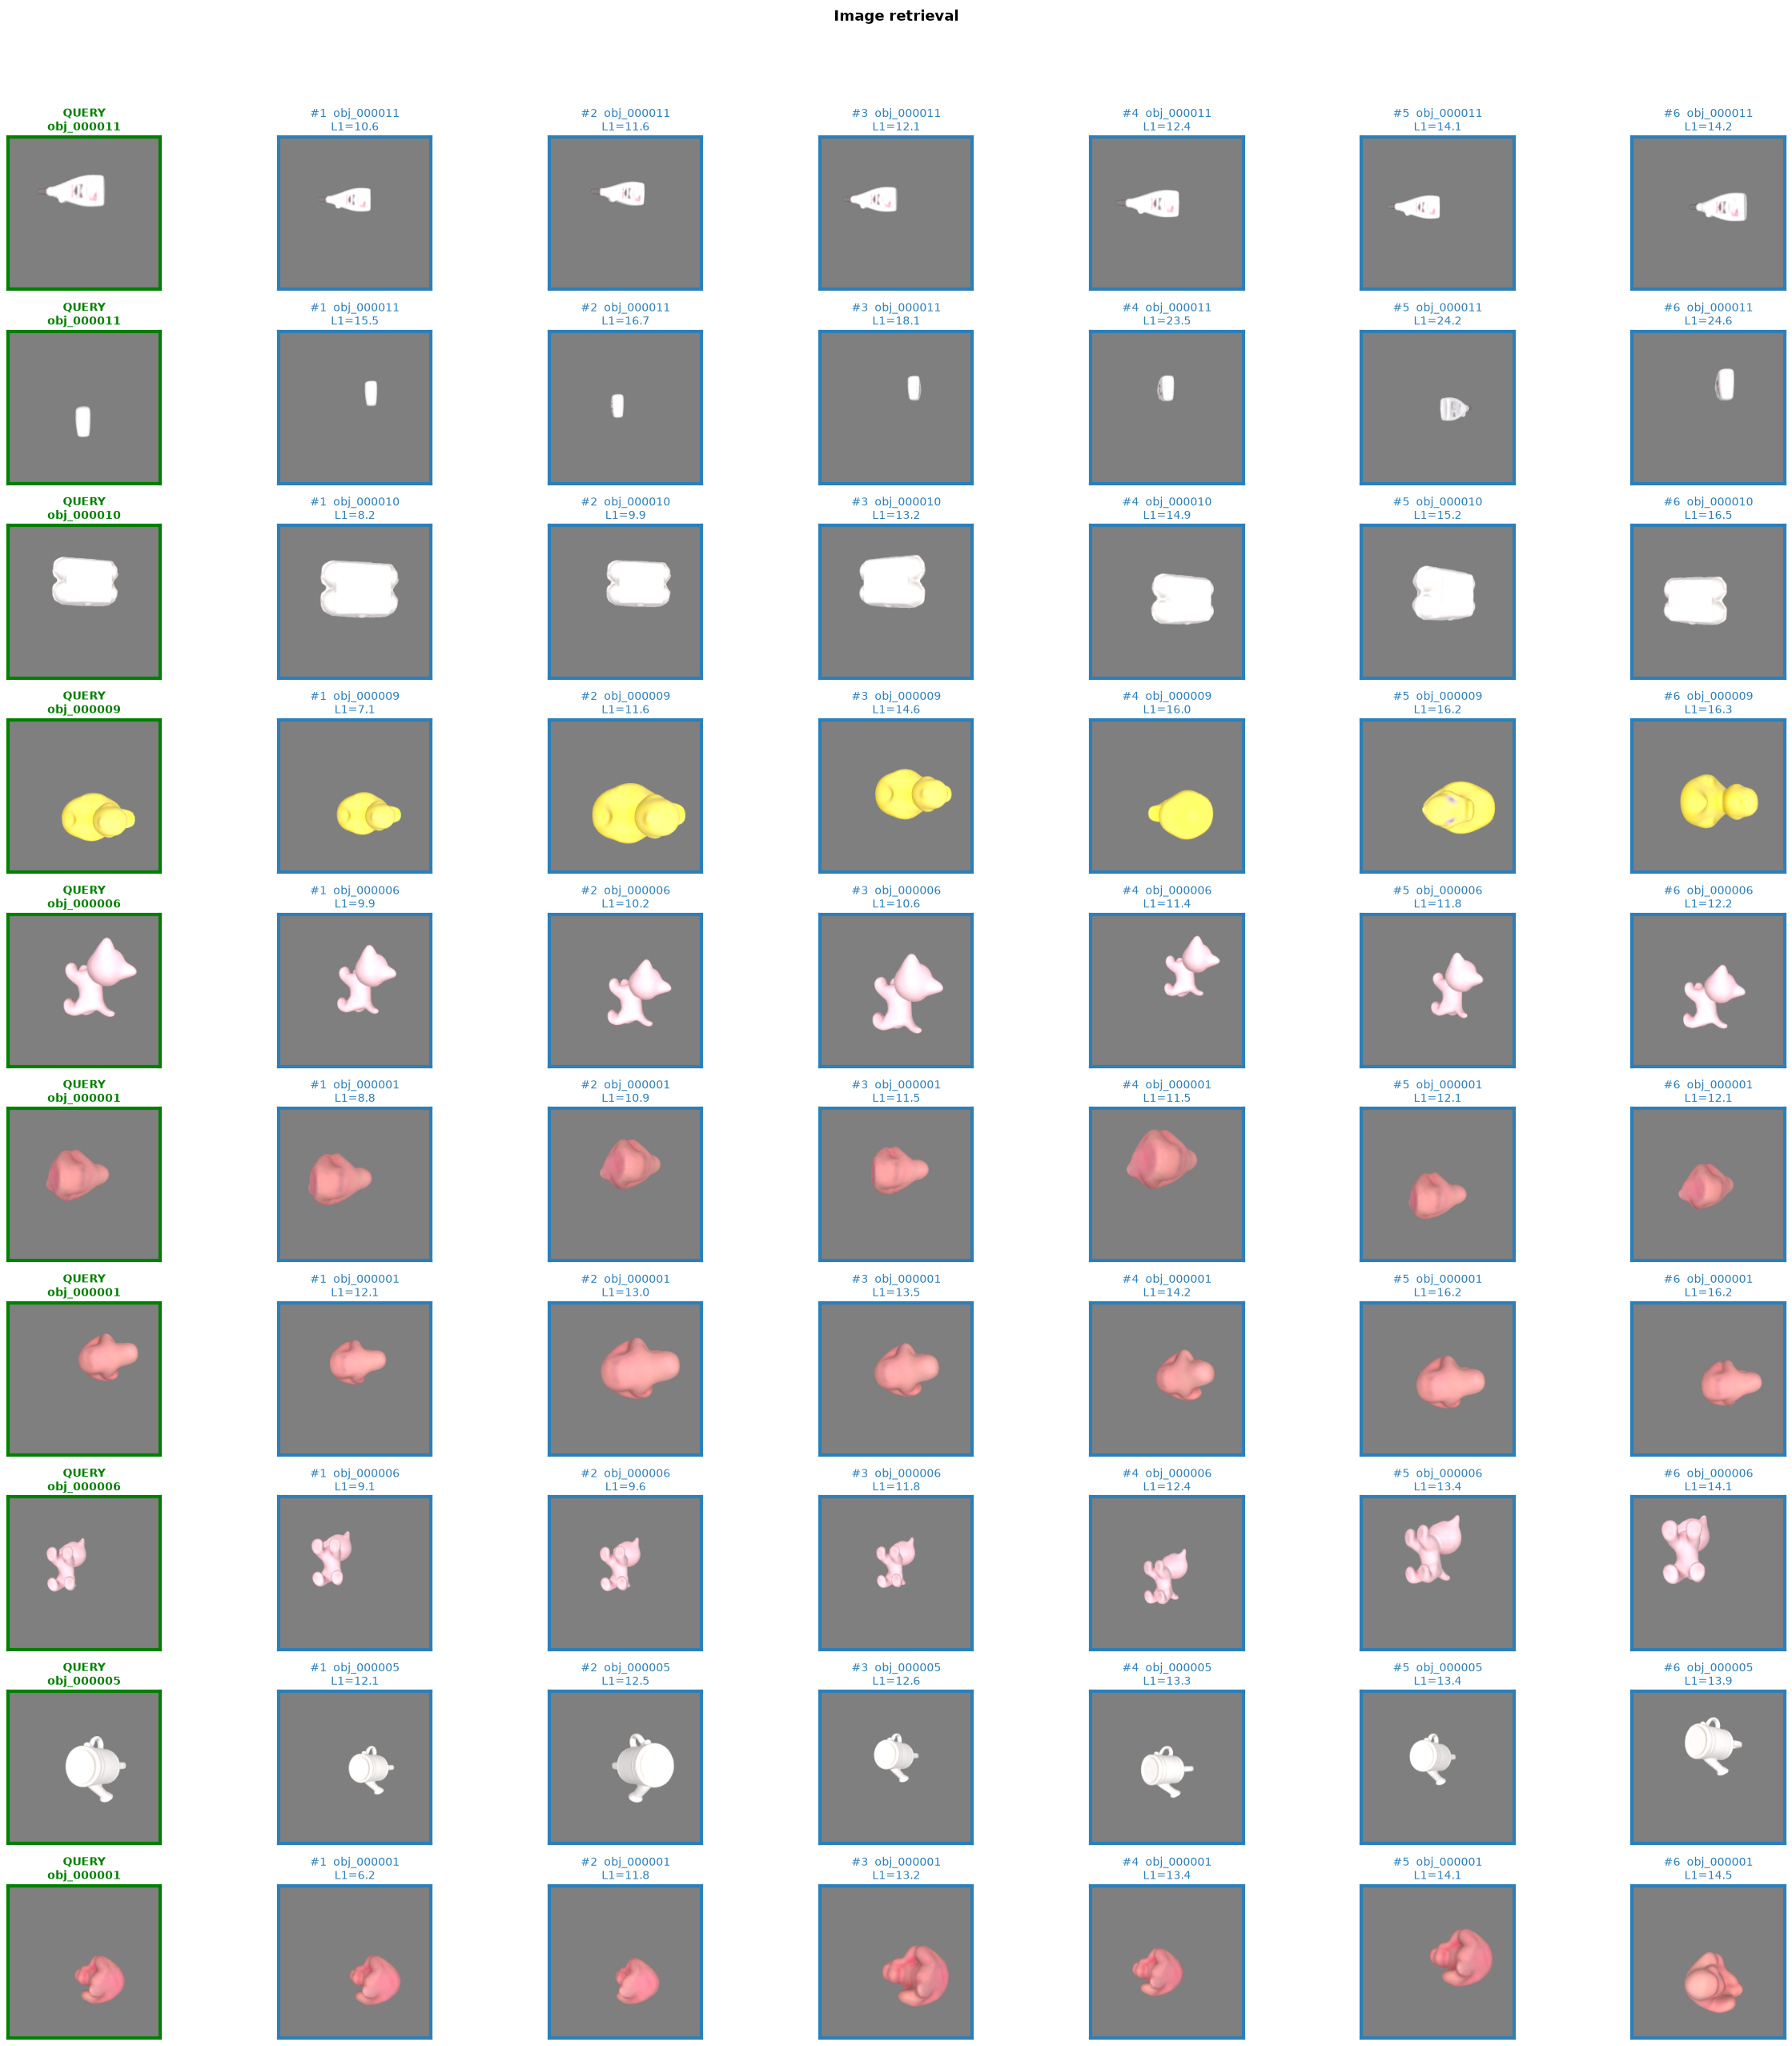

In [14]:

DATASET = "lmo"          
TOKEN   = "pool"
GRID    = 2
SEED    = 0

# --- NUOVI PARAMETRI CONFIGURABILI ---
NUM_QUERIES = 10  # Numero di oggetti/query da visualizzare (righe)
TOP_K       = 6  # Numero di output più simili da restituire (colonne extra)

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv").reset_index(drop=True)

# --- Costruisci la galleria: embedding di TUTTE le immagini ---
print(f"Calcolo embedding di {len(df)} immagini...")
gallery = []
for i in range(len(df)):
    e = extract_features2(Image.open(RENDERS / df.iloc[i]["image"]).convert("RGB"),
                          token=TOKEN, grid=GRID)
    gallery.append(e)
gallery = torch.stack(gallery)        # (N, D)

# --- Estrazione query casuali ---
rng = np.random.default_rng(SEED)
queries = rng.choice(len(df), size=NUM_QUERIES, replace=False)

# --- Impostazione dinamica della griglia ---
# Righe = NUM_QUERIES
# Colonne = 1 (Query) + TOP_K (Risultati)
# Figsize si adatta dinamicamente per evitare immagini schiacciate
fig, axes = plt.subplots(NUM_QUERIES, TOP_K + 1, figsize=(3.5 * (TOP_K + 1), 2.5 * NUM_QUERIES))

# Gestione del caso limite in cui NUM_QUERIES = 1 (matplotlib restituisce un array 1D)
if NUM_QUERIES == 1:
    axes = np.expand_dims(axes, axis=0)

for r, q in enumerate(queries):
    # Distanza L1 della query da TUTTA la galleria
    d = torch.abs(gallery - gallery[q]).sum(dim=1)
    d[q] = float("inf")               # Escludi se stessa
    
    # Prendi solo i primi TOP_K risultati
    top = torch.argsort(d)[:TOP_K].cpu().numpy()

    # Colonna 0 = Query
    qrow = df.iloc[q]
    axes[r, 0].imshow(Image.open(RENDERS / qrow["image"]).convert("RGB"))
    axes[r, 0].set_title(f"QUERY\n{qrow['object']}", fontsize=10, color="green", fontweight="bold")
    for s in axes[r, 0].spines.values(): 
        s.set_color("green")
        s.set_linewidth(3)
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])

    # Colonne 1 fino a TOP_K = i più vicini
    for k, idx in enumerate(top):
        row = df.iloc[idx]
        
        # Verde se stesso oggetto della query, arancio se diverso
        same = (row["object"] == qrow["object"])
        col = "#2c7fb8" if same else "#d95f0e"
        
        axes[r, k+1].imshow(Image.open(RENDERS / row["image"]).convert("RGB"))
        axes[r, k+1].set_title(f"#{k+1}  {row['object']}\nL1={d[idx]:.1f}", fontsize=10, color=col)
        for s in axes[r, k+1].spines.values(): 
            s.set_color(col)
            s.set_linewidth(3)
        axes[r, k+1].set_xticks([])
        axes[r, k+1].set_yticks([])

# Titolo generale
plt.suptitle(
    f"Image retrieval\n", 
    y=1.02, fontsize=13, fontweight="bold"
)

plt.tight_layout()
plt.show()

# SIM TO REAL -- GAP (If we move to occlusion and real scene it reduces performance????)


In [18]:
import sys
import json
import numpy as np
from PIL import Image

sys.path.append("/Experiments/riccardop02")
from JEPA.Essential.path import scene_gt, scene_camera, get_registered_detection, rgb_file, mask_visib, detection_file, model_file

METHOD = "cnos"
DATASET_NAME = "ycbv"
SPLIT = "test"

try:
    det_path = get_registered_detection(METHOD, DATASET_NAME, SPLIT)
except KeyError as e:
    print(f"[ERROR] {e}")
    sys.exit(1)

with open(det_path, 'r') as f:
    dets = json.load(f)

d0 = dets[0]
sid, iid = d0["scene_id"], d0["image_id"]
image_id_str = str(iid)

print(f"--- {METHOD.upper()} [0] ---")
print({k: d0[k] for k in ["scene_id", "image_id", "category_id", "bbox", "score"]})

gt_path = scene_gt(DATASET_NAME, sid, split=SPLIT)
cam_path = scene_camera(DATASET_NAME, sid, split=SPLIT)

with open(gt_path, 'r') as f:
    gt = json.load(f)
with open(cam_path, 'r') as f:
    cam = json.load(f)

if image_id_str in gt:
    gt_obj_ids = [o["obj_id"] for o in gt[image_id_str]]
    pred_id = d0['category_id']
    
    print(f"GT objects : {gt_obj_ids}")
    print(f"Prediction : {pred_id}")
    print(f"Match      : {pred_id in gt_obj_ids}")
    print(f"K:\n{np.array(cam[image_id_str]['cam_K']).reshape(3,3)}")
else:
    print(f"[ERROR] image_id {iid} not found in GT.")

--- CNOS [0] ---
{'scene_id': 48, 'image_id': 1024, 'category_id': 1, 'bbox': [339, 170, 96, 133], 'score': 0.7473174929618835}
GT objects : [1, 6, 14, 19, 20]
Prediction : 1
Match      : True
K:
[[1.066778e+03 0.000000e+00 3.129869e+02]
 [0.000000e+00 1.067487e+03 2.413109e+02]
 [0.000000e+00 0.000000e+00 1.000000e+00]]


In [19]:
import pycocotools.mask as coco_mask

METHOD = "cnos"
DATASET_NAME = "ycbv"
SPLIT = "test"

def load_real(scene_id: int, image_id: int, dataset=DATASET_NAME, split=SPLIT):
    return Image.open(rgb_file(dataset, scene_id, image_id, split=split)).convert("RGB")

def load_K(scene_id: int, image_id: int, dataset=DATASET_NAME, split=SPLIT):
    with open(scene_camera(dataset, scene_id, split=split), 'r') as f:
        cam = json.load(f)
    return np.array(cam[str(image_id)]["cam_K"]).reshape(3, 3)

def load_gt_poses(scene_id: int, image_id: int, dataset=DATASET_NAME, split=SPLIT):
    with open(scene_gt(dataset, scene_id, split=split), 'r') as f:
        gt = json.load(f)
    
    out = []
    for o in gt[str(image_id)]:
        R = np.array(o["cam_R_m2c"]).reshape(3, 3)
        t = np.array(o["cam_t_m2c"]).reshape(3)
        out.append((o["obj_id"], R, t))
    return out

def rle_to_mask(seg: dict):
    if isinstance(seg["counts"], list):
        seg = coco_mask.frPyObjects(seg, seg["size"][0], seg["size"][1])
    return coco_mask.decode(seg).astype(bool)

def load_gt_mask(scene_id: int, image_id: int, obj_idx: int, dataset=DATASET_NAME, split=SPLIT):
    m = Image.open(mask_visib(dataset, scene_id, image_id, obj_idx, split=split))
    return np.array(m).astype(bool)


try:
    det_path = get_registered_detection(METHOD, DATASET_NAME, SPLIT)
except KeyError as e:
    print(f"[ERROR] {e}")
    sys.exit(1)

with open(det_path, 'r') as f:
    dets = json.load(f)

d0 = dets[0]
sid, iid = d0["scene_id"], d0["image_id"]

img = load_real(sid, iid)
K = load_K(sid, iid)
poses = load_gt_poses(sid, iid)

print(f"--- {METHOD.upper()} [0] ---")
print(f"Image Size : {img.size}")
print(f"K Focal X  : {K[0,0]:.0f}")
print(f"GT Objects : {[p[0] for p in poses]}")

mask_cnos = rle_to_mask(d0["segmentation"])
print(f"CNOS Mask  : {mask_cnos.shape} (Active pixels: {mask_cnos.sum()})")

--- CNOS [0] ---
Image Size : (640, 480)
K Focal X  : 1067
GT Objects : [1, 6, 14, 19, 20]
CNOS Mask  : (480, 640) (Active pixels: 11008)


[INFO] Rendering obj_id 1 at Ground Truth pose...


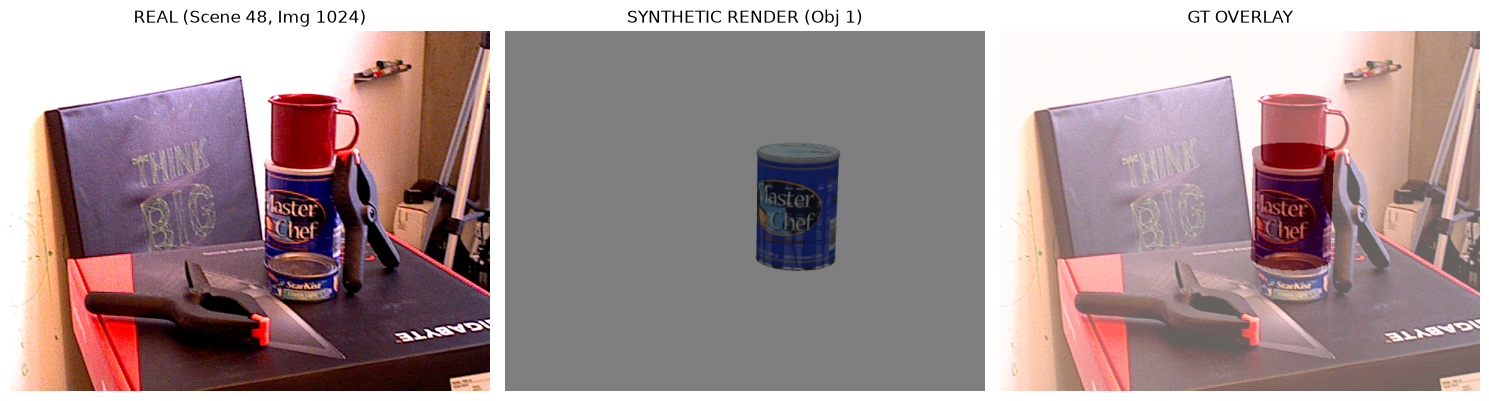

In [21]:
import os
os.environ["PYOPENGL_PLATFORM"] = "egl"
import trimesh
import pyrender
import matplotlib.pyplot as plt

IMG_W, IMG_H = 640, 480
BG_GRAY = 0.5
_MESH_CACHE = {}

try:
    _RENDERER = pyrender.OffscreenRenderer(IMG_W, IMG_H)
except Exception as e:
    print(f"[WARNING] Failed to initialize EGL renderer. Rendering bypassed: {e}")
    _RENDERER = None

def _intrinsics_camera(K: np.ndarray, znear=1.0, zfar=10000.0):
    fx, fy = K[0,0], K[1,1]
    cx, cy = K[0,2], K[1,2]
    return pyrender.IntrinsicsCamera(fx=fx, fy=fy, cx=cx, cy=cy, znear=znear, zfar=zfar)

def _add_raymond_lights(scene: pyrender.Scene):
    thetas = np.pi * np.array([1/6, 1/6, 1/6])
    phis = np.pi * np.array([0, 2/3, 4/3])
    
    for th, ph in zip(thetas, phis):
        z = np.array([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)])
        z /= np.linalg.norm(z)
        x = np.array([-z[1], z[0], 0.0])
        x = x / np.linalg.norm(x) if np.linalg.norm(x) > 1e-8 else np.array([1., 0, 0])
        y = np.cross(z, x)
        
        pose = np.eye(4)
        pose[:3, :3] = np.c_[x, y, z]
        scene.add(pyrender.DirectionalLight(color=np.ones(3), intensity=2.5), pose=pose)

def _get_mesh(obj_id: int, dataset=DATASET_NAME):
    if obj_id not in _MESH_CACHE:
        tm = trimesh.load(model_file(dataset, obj_id), force="mesh")
        _MESH_CACHE[obj_id] = pyrender.Mesh.from_trimesh(tm, smooth=False)
    return _MESH_CACHE[obj_id]

def render_at_pose(obj_id: int, R: np.ndarray, t: np.ndarray, K: np.ndarray, dataset=DATASET_NAME):
    if _RENDERER is None:
        return Image.new('RGB', (IMG_W, IMG_H), (0, 0, 0)), np.zeros((IMG_H, IMG_W), dtype=bool)

    scene = pyrender.Scene(bg_color=np.array([BG_GRAY]*3), ambient_light=np.array([0.35]*3))
    scene.add(_get_mesh(obj_id, dataset), pose=np.eye(4))
    _add_raymond_lights(scene)

    M = np.eye(4)
    M[:3, :3] = R
    M[:3, 3] = t
    
    cv_to_gl = np.diag([1, -1, -1, 1]).astype(float)
    cam_pose = np.linalg.inv(cv_to_gl @ M)

    cam = _intrinsics_camera(K)
    scene.add(cam, pose=cam_pose)

    try:
        color, depth = _RENDERER.render(scene)
        mask = depth > 0
        return Image.fromarray(color), mask
    except Exception as e:
        print(f"[WARNING] EGL Render Context Failed. Bypassing visualization: {e}")
        return Image.new('RGB', (IMG_W, IMG_H), (0, 0, 0)), np.zeros((IMG_H, IMG_W), dtype=bool)

if __name__ == "__main__":
    if 'poses' in locals() and len(poses) > 0:
        obj_id, R_gt, t_gt = poses[0]
        
        print(f"[INFO] Rendering obj_id {obj_id} at Ground Truth pose...")
        rend_img, rend_mask = render_at_pose(obj_id, R_gt, t_gt, K)

        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        
        ax[0].imshow(img)
        ax[0].set_title(f"REAL (Scene {sid}, Img {iid})")
        ax[0].axis("off")
        
        ax[1].imshow(rend_img)
        ax[1].set_title(f"SYNTHETIC RENDER (Obj {obj_id})")
        ax[1].axis("off")
        
        ax[2].imshow(img)
        if rend_mask.any():
            ax[2].imshow(rend_mask, alpha=0.4, cmap="Reds")
        ax[2].set_title("GT OVERLAY")
        ax[2].axis("off")
        
        plt.tight_layout()
        plt.show()
    else:
        print("[WARNING] No Ground Truth poses found for this image.")

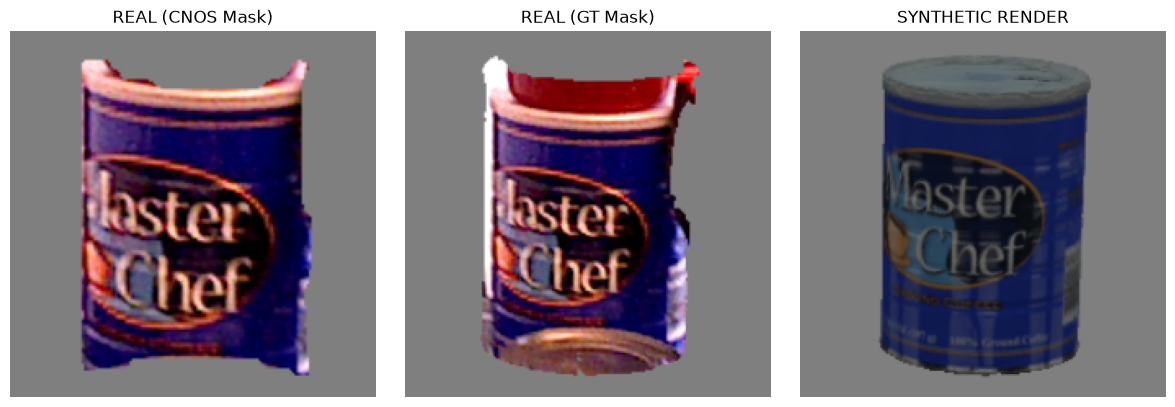

In [22]:
def crop_and_mask(
    img: Image.Image, 
    mask: np.ndarray, 
    bbox: list = None, 
    out_size: int = 224, 
    pad: float = 0.15, 
    bg: float = 0.5
) -> Image.Image:
    
    arr = np.array(img).astype(np.float32)
    m = mask.astype(bool)

    arr[~m] = bg * 255.0

    if bbox is not None:
        x, y, w, h = bbox
    else:
        ys, xs = np.where(m)
        if len(ys) == 0 or len(xs) == 0:
            return Image.new('RGB', (out_size, out_size), int(bg * 255))
        x, y = xs.min(), ys.min()
        w, h = xs.max() - x, ys.max() - y

    cx, cy = x + w / 2.0, y + h / 2.0
    side = max(w, h) * (1.0 + pad)
    
    x0, y0 = int(cx - side / 2.0), int(cy - side / 2.0)
    x1, y1 = int(cx + side / 2.0), int(cy + side / 2.0)

    H, W = arr.shape[:2]
    canvas = np.full((y1 - y0, x1 - x0, 3), bg * 255.0, dtype=np.float32)
    
    sx0, sy0 = max(0, x0), max(0, y0)
    sx1, sy1 = min(W, x1), min(H, y1)
    
    canvas_y0, canvas_y1 = sy0 - y0, sy1 - y0
    canvas_x0, canvas_x1 = sx0 - x0, sx1 - x0
    
    if canvas_y1 > canvas_y0 and canvas_x1 > canvas_x0:
        canvas[canvas_y0:canvas_y1, canvas_x0:canvas_x1] = arr[sy0:sy1, sx0:sx1]

    return Image.fromarray(canvas.astype(np.uint8)).resize((out_size, out_size), Image.Resampling.BILINEAR)

if __name__ == "__main__":
    real_cnos = crop_and_mask(img, mask_cnos, bbox=d0["bbox"])
    
    try:
        obj_idx = gt_obj_ids.index(pred_id)
        mask_gt = load_gt_mask(sid, iid, obj_idx)
        real_gt = crop_and_mask(img, mask_gt)
    except ValueError:
        print(f"[WARNING] Predicted category {pred_id} not found in GT list. Skipping GT crop.")
        real_gt = Image.new('RGB', (224, 224), int(BG_GRAY * 255))

    if 'rend_img' in locals() and 'rend_mask' in locals():
        rend_crop = crop_and_mask(rend_img, rend_mask)
    else:
        rend_crop = Image.new('RGB', (224, 224), int(BG_GRAY * 255))

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    
    ax[0].imshow(real_cnos)
    ax[0].set_title("REAL (CNOS Mask)")
    ax[0].axis("off")
    
    ax[1].imshow(real_gt)
    ax[1].set_title("REAL (GT Mask)")
    ax[1].axis("off")
    
    ax[2].imshow(rend_crop)
    ax[2].set_title("SYNTHETIC RENDER")
    ax[2].axis("off")
    
    plt.tight_layout()
    plt.show()


=== Processing Scene 48, Image 1024 ===


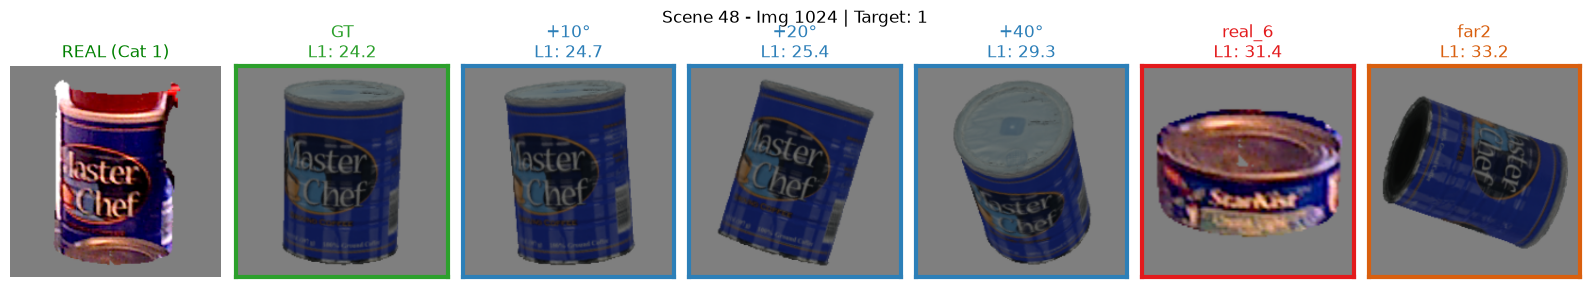

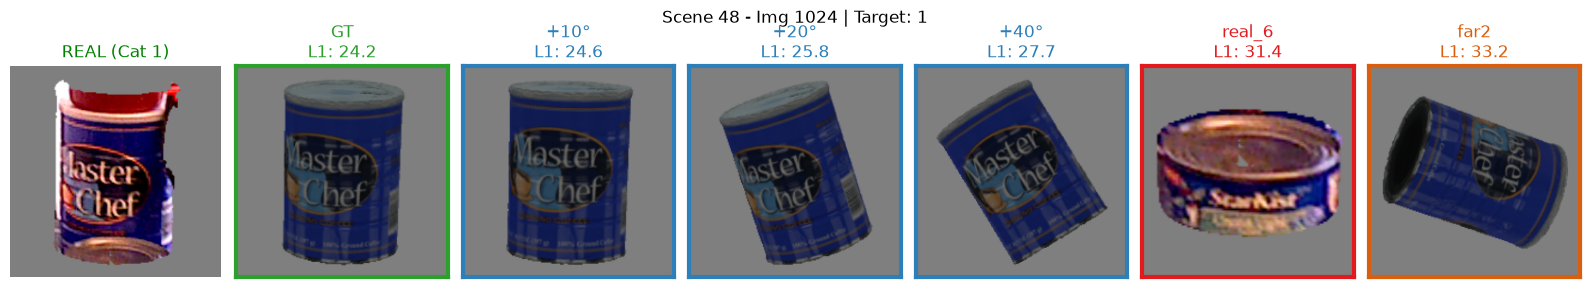

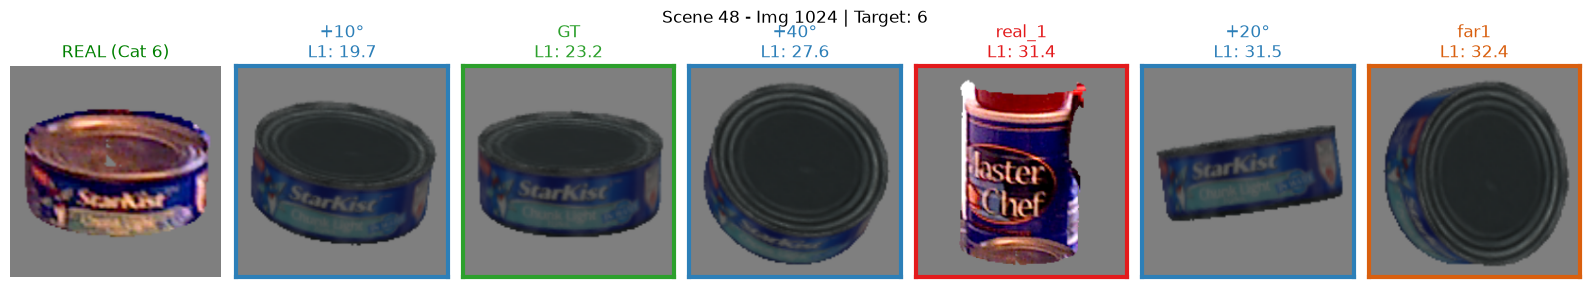

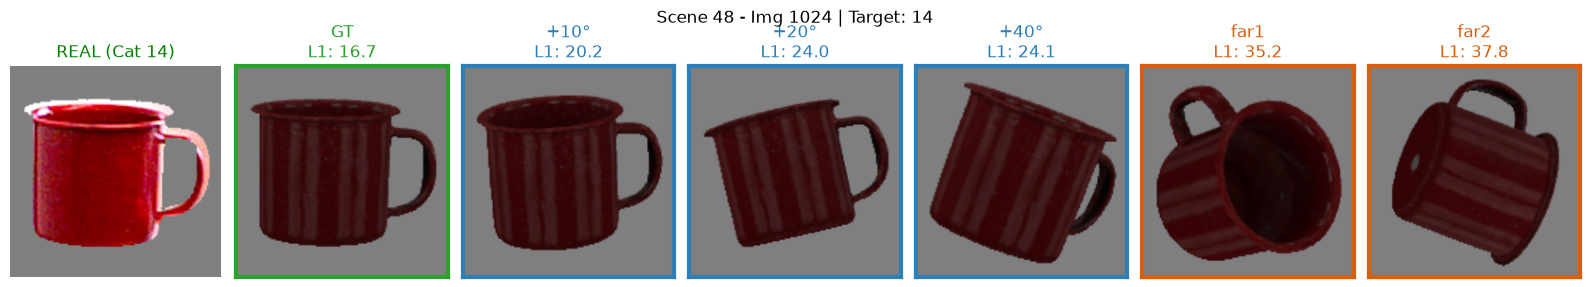

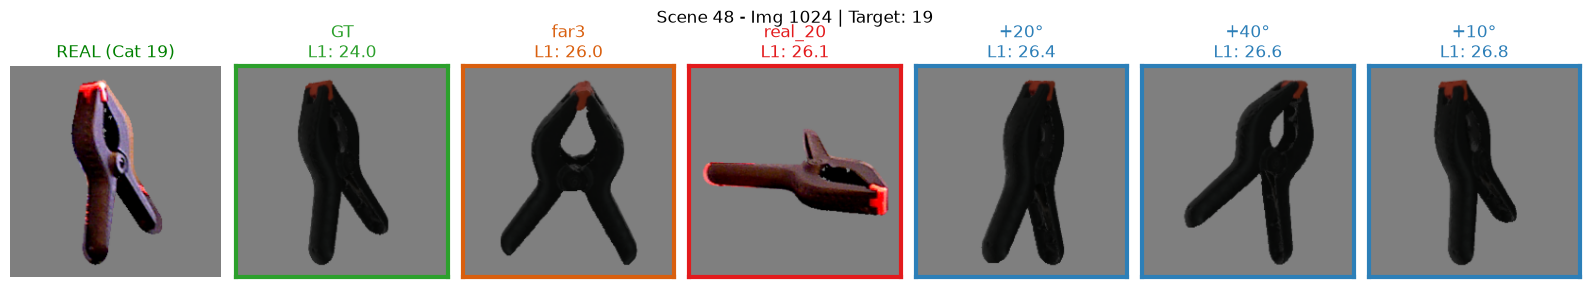

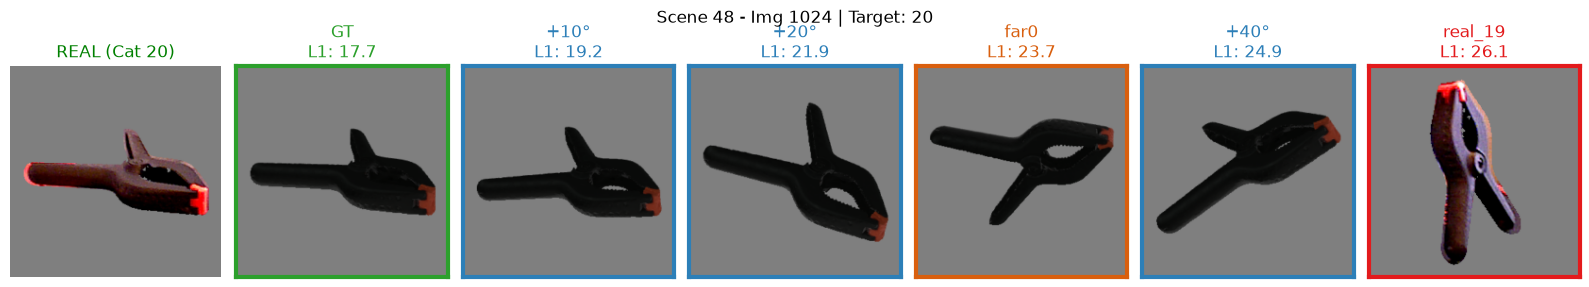

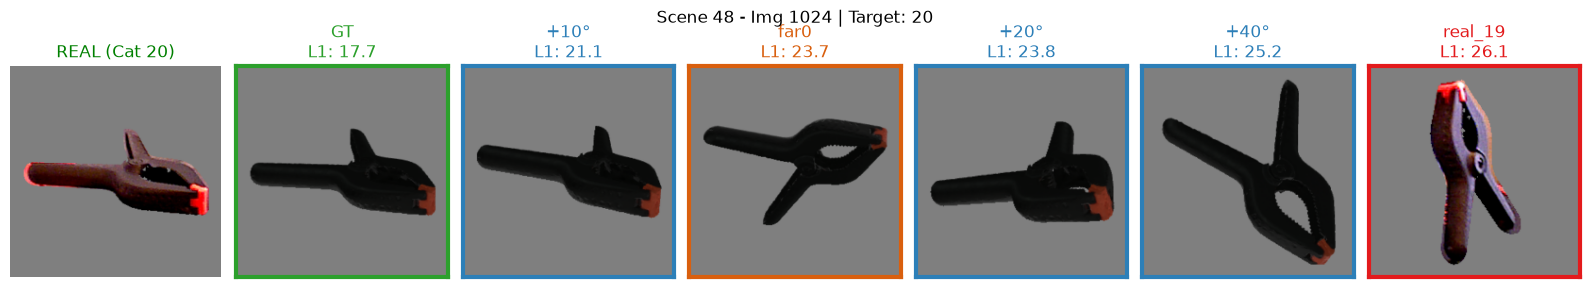

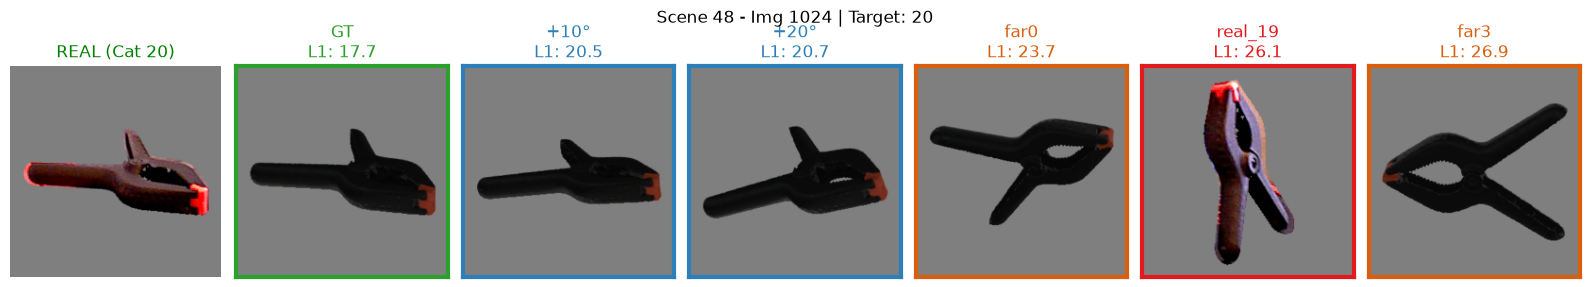

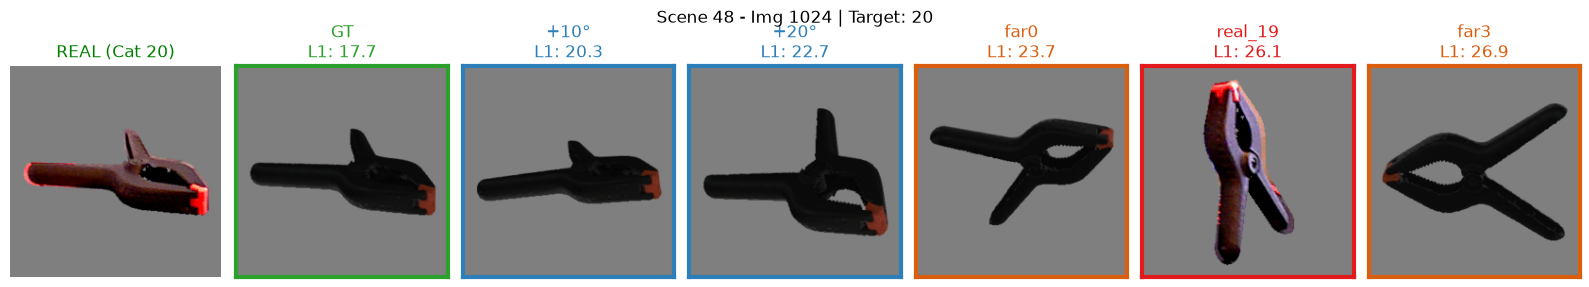


=== Processing Scene 50, Image 1026 ===


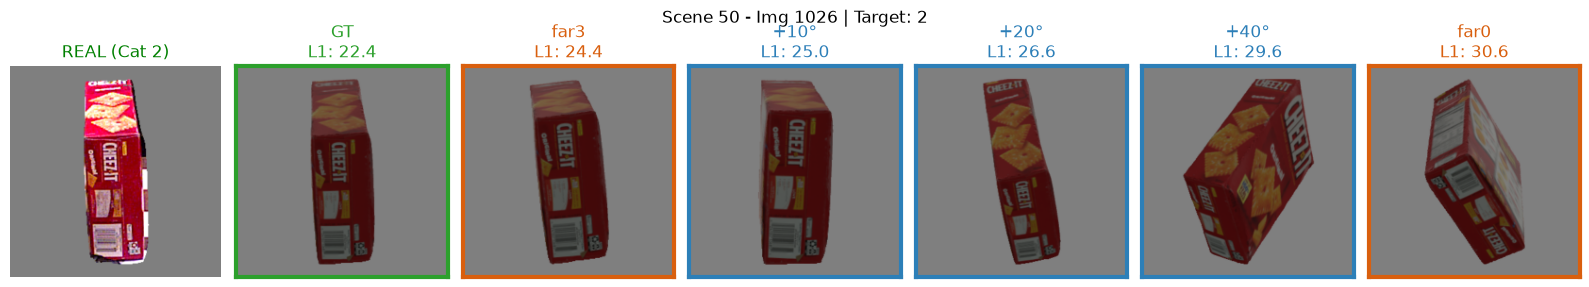

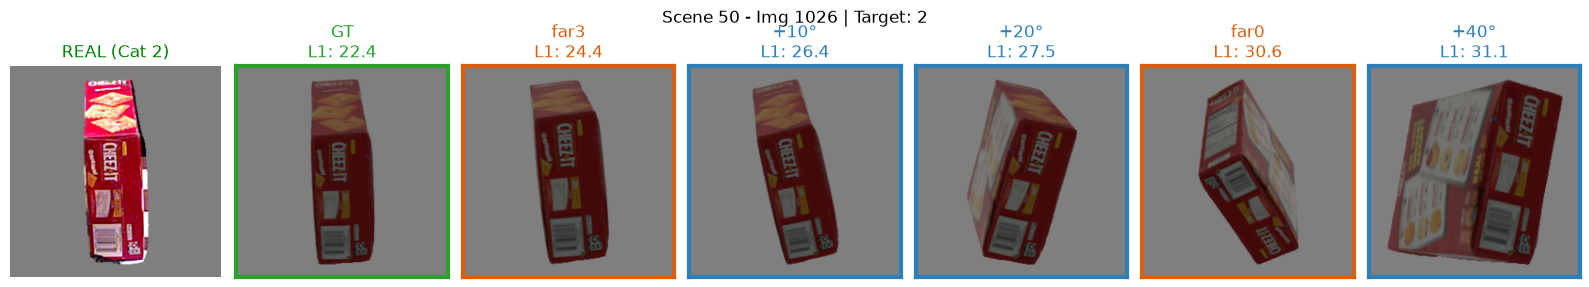

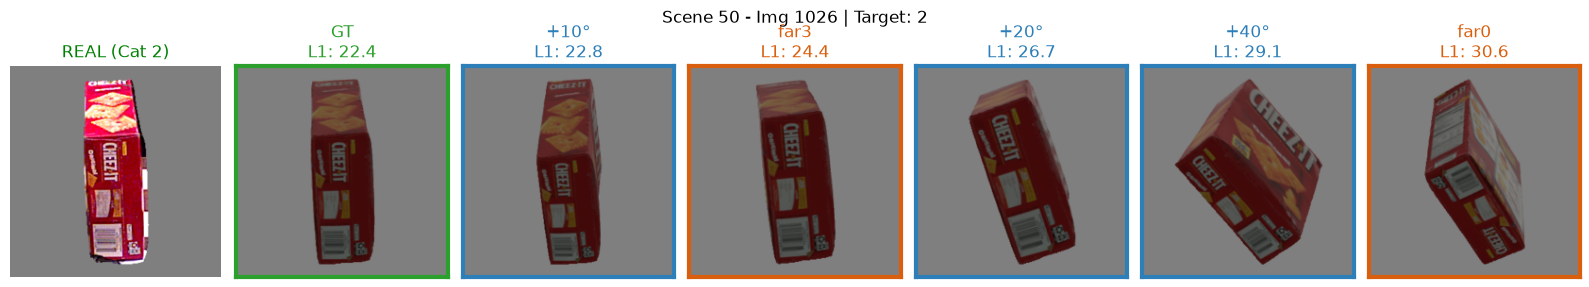

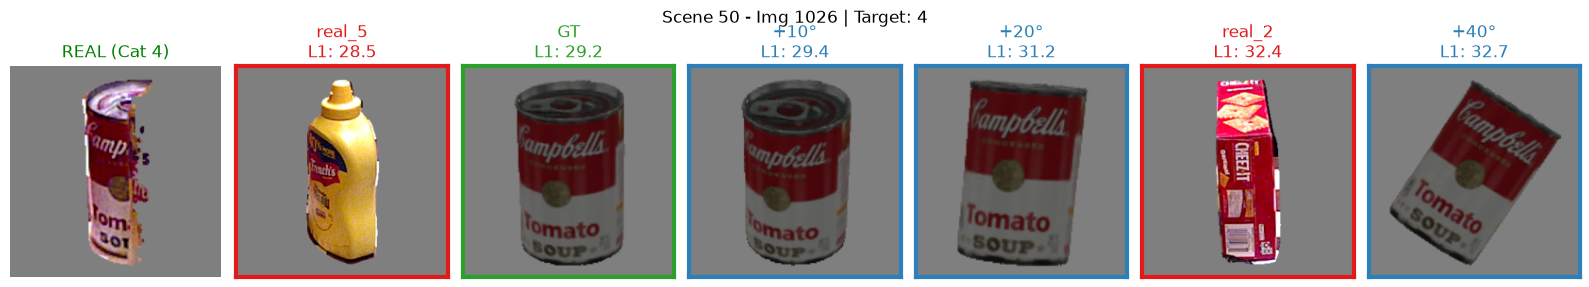

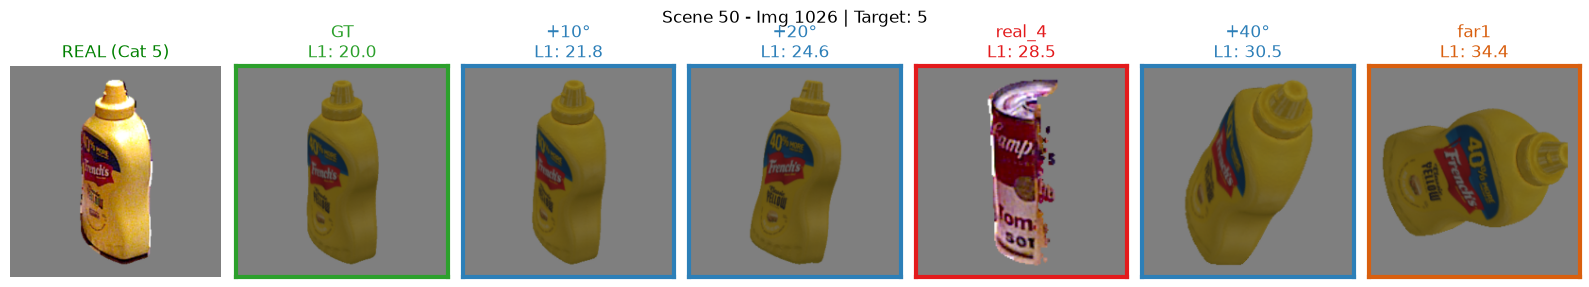

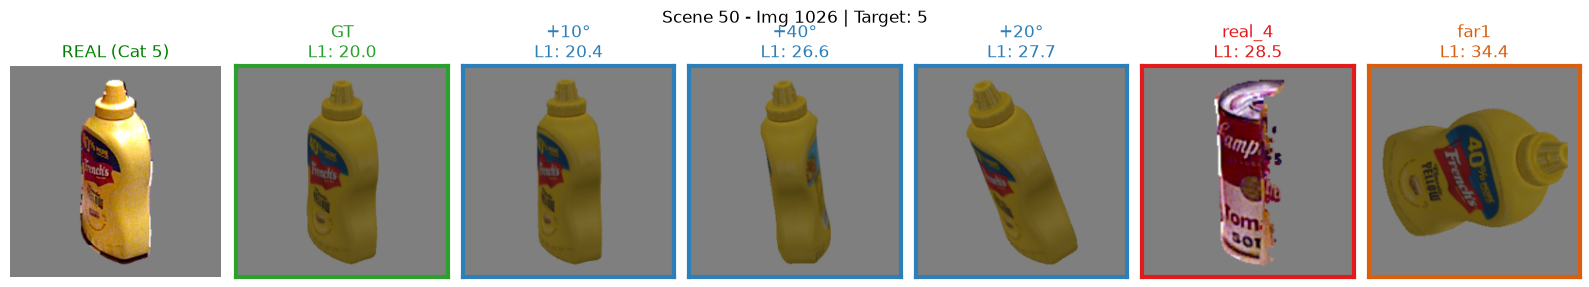

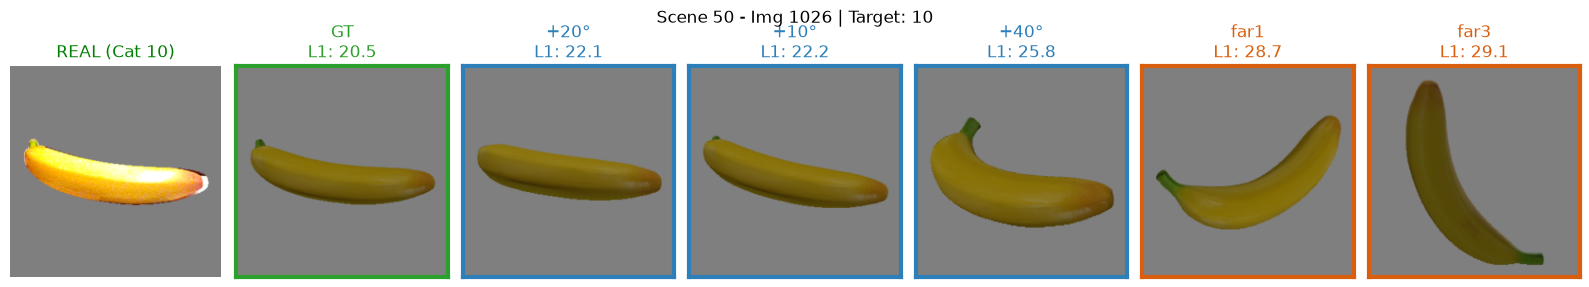

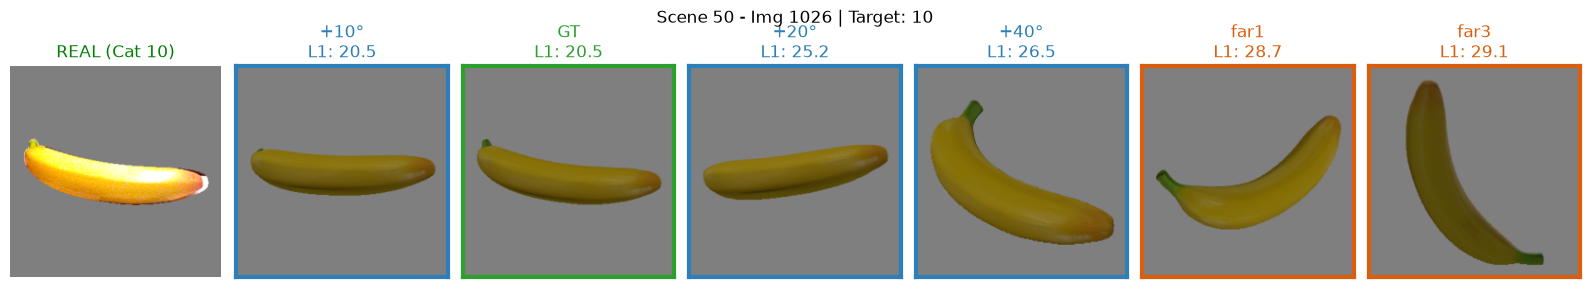

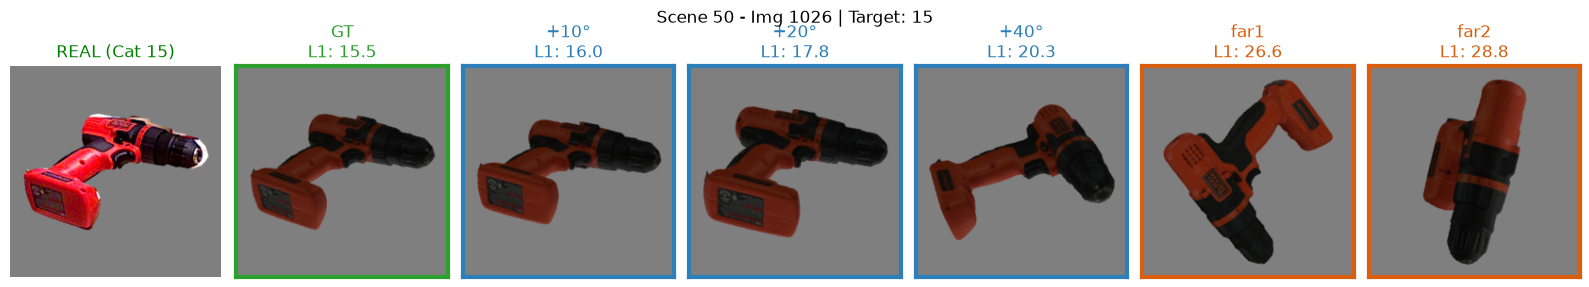

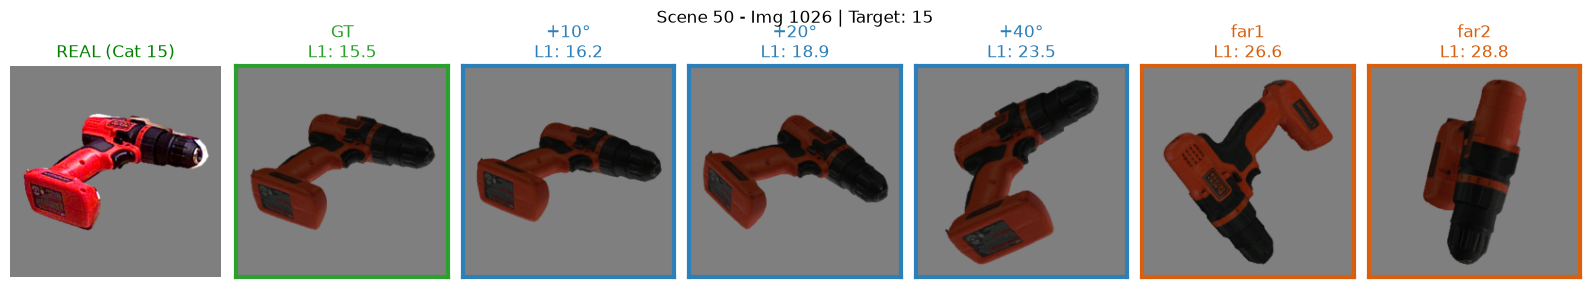

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation

# ==========================================
# 1. FUNZIONI DI SUPPORTO E CANDIDATI
# ==========================================

def perturb_pose(R, t, deg):
    """Ruota R di 'deg' gradi attorno a un asse casuale (posa vicina)."""
    axis = np.random.randn(3)
    axis /= np.linalg.norm(axis)
    dR = Rotation.from_rotvec(np.deg2rad(deg) * axis).as_matrix()
    return dR @ R, t

def build_candidates(scene_id, image_id, cat_obj, K, all_obj_ids,
                     near_degs=(10, 20, 40), n_far=4, n_other=4, seed=0):

    rng = np.random.default_rng(seed)
    poses = load_gt_poses(scene_id, image_id)
    R_gt, t_gt = next((R, t) for (oid, R, t) in poses if oid == cat_obj)

    cand = []
    # GT
    rend, m = render_at_pose(cat_obj, R_gt, t_gt, K)
    cand.append(("GT", "gt", crop_and_mask(rend, m)))
    
    # vicine
    for dg in near_degs:
        Rp, tp = perturb_pose(R_gt, t_gt, dg)
        rend, m = render_at_pose(cat_obj, Rp, tp, K)
        cand.append((f"+{dg}°", "near", crop_and_mask(rend, m)))
        
    # lontane (stesso oggetto, pose random)
    for k in range(n_far):
        Rr = Rotation.random(random_state=rng.integers(1e6)).as_matrix()
        rend, m = render_at_pose(cat_obj, Rr, t_gt, K)
        cand.append((f"far{k}", "far", crop_and_mask(rend, m)))
        
    # altri oggetti (pose random)
    others = [o for o in all_obj_ids if o != cat_obj]
    for k, oid in enumerate(rng.choice(others, size=min(n_other, len(others)), replace=False)):
        Rr = Rotation.random(random_state=rng.integers(1e6)).as_matrix()
        rend, m = render_at_pose(int(oid), Rr, t_gt, K)
        cand.append((f"obj{oid}", "other", crop_and_mask(rend, m)))
        
    return cand

def get_bg_distractors(img, mask_gt, num=2, crop_size=(128, 128), seed=42):
    """
    Estrae patch di sfondo dall'immagine reale dove la mask_gt è 0.
    Ritorna una lista di immagini ritagliate.
    """
    rng = np.random.default_rng(seed)
    # img può essere un'immagine PIL o un array numpy
    img_np = np.array(img)
    h, w = img_np.shape[:2]
    bg_crops = []
    
    # Trova i pixel che appartengono sicuramente allo sfondo
    bg_mask = (mask_gt == 0)
    
    attempts = 0
    while len(bg_crops) < num and attempts < 100:
        attempts += 1
        # Genera un punto in alto a sinistra casuale per il crop
        x = rng.integers(0, w - crop_size[0])
        y = rng.integers(0, h - crop_size[1])
        
        # Controlla se la patch selezionata contiene principalmente sfondo
        mask_patch = bg_mask[y:y+crop_size[1], x:x+crop_size[0]]
        if np.mean(mask_patch) > 0.95:  # Almeno il 95% della patch deve essere sfondo
            crop = img_np[y:y+crop_size[1], x:x+crop_size[0]]
            # Se l'originale usa PIL, convertiamo in PIL Image per coerenza con crop_and_mask
            from PIL import Image
            bg_crops.append(Image.fromarray(crop))
            
    # Fallback se non trova patch pulite: prende crop casuali generici
    while len(bg_crops) < num:
        x = rng.integers(0, w - crop_size[0])
        y = rng.integers(0, h - crop_size[1])
        crop = img_np[y:y+crop_size[1], x:x+crop_size[0]]
        from PIL import Image
        bg_crops.append(Image.fromarray(crop))
        
    return bg_crops

# ==========================================
# 2. PIPELINE DI EVALUATION / ESPERIMENTO
# ==========================================

TOKEN = "pool"
GRID = 2

test_images = [(48, 1024), (50, 1026)]
all_obj_ids = sorted({d["category_id"] for d in dets})

for sid, iid in test_images:
    print(f"\n=== Processing Scene {sid}, Image {iid} ===")
    
    img = load_real(sid, iid)
    K = load_K(sid, iid)
    poses = load_gt_poses(sid, iid)
    gt_obj_ids = [p[0] for p in poses] # Keep track of all real objects in this image
    
    img_dets = [d for d in dets if d["scene_id"] == sid and d["image_id"] == iid]
    if not img_dets:
        continue

    for idx, det in enumerate(img_dets):
        cat = det["category_id"]
        
        try:
            obj_idx = gt_obj_ids.index(cat)
            mask_gt = load_gt_mask(sid, iid, obj_idx)
            real_gt = crop_and_mask(img, mask_gt)
        except ValueError:
            continue
            
        e_real = extract_features2(real_gt, token=TOKEN, grid=GRID)
        
        # 1. Get Synthetic Candidates (GT, Near, Far, Other)
        cand_list = build_candidates(sid, iid, cat, K, all_obj_ids)
        
        # 2. Inject Distractors: Background Crops
        bg_crops = get_bg_distractors(img, mask_gt, num=2)
        for k, crop in enumerate(bg_crops):
            cand_list.append((f"bg_{k}", "distractor", crop))
            
        # 3. Inject Distractors: Other REAL objects in the same image
        for other_cat in gt_obj_ids:
            if other_cat != cat:
                other_idx = gt_obj_ids.index(other_cat)
                other_mask = load_gt_mask(sid, iid, other_idx)
                other_crop = crop_and_mask(img, other_mask)
                cand_list.append((f"real_{other_cat}", "distractor", other_crop))
        
        # Calculate L1 distances for all candidates + distractors
        rows = []
        for label, kind, im in cand_list:
            e = extract_features2(im, token=TOKEN, grid=GRID)
            l1_dist = torch.abs(e_real - e).sum().item()
            rows.append((label, kind, l1_dist, im))

        rows.sort(key=lambda x: x[2])
        top_candidates = rows[:6] # Increased to 6 to see if distractors sneak in

        fig, ax = plt.subplots(1, 7, figsize=(16, 3))
        
        ax[0].imshow(real_gt)
        ax[0].set_title(f"REAL (Cat {cat})", color="green")
        ax[0].axis("off")
        
        # Color map aggiornata inclusi i distractor (rosso)
        color_map = {"gt": "#2ca02c", "near": "#2c7fb8", "far": "#d95f0e", "other": "#777777", "distractor": "#e31a1c"}
        
        for j, (label, kind, l1_dist, im) in enumerate(top_candidates):
            ax[j+1].imshow(im)
            ax[j+1].set_title(f"{label}\nL1: {l1_dist:.1f}", color=color_map.get(kind, "black"))
            for spine in ax[j+1].spines.values():
                spine.set_color(color_map.get(kind, "black"))
                spine.set_linewidth(3)
            ax[j+1].set_xticks([])
            ax[j+1].set_yticks([])
            
        plt.suptitle(f"Scene {sid} - Img {iid} | Target: {cat}")
        plt.tight_layout()
        plt.show()